# 04 BRtest vs FM100

Design: `docs/superpowers/specs/2026-11-12-blueredlinear-brtest-design.md`.
Each value is an FBCCA score for one 3 s epoch.

Measures:
- `raw`: FBCCA score.
- `norm`: score / baseline, where baseline = `BASE_STAT` (median by default) of
  that participant x session x filter's 8-trial base run (red 1800 vs blue 0).
  1 = as strong as red against nothing. NF is divided by `base_NF`, YF by `base_YF`.
- Floor (mean of the 4 leading non-flicker trials: 2 per rep x 2 reps) is shown
  for reference only (FBCCA chance level); it is not used in any measure.

Blue-axis windows: `mean` = all 11 steps, `low` = first 3 (0, 170, 340),
`high` = last 3 (1360, 1530, 1700).

Updating: every `MET*.mat` in the BRtest folder is picked up (suffix `b` =
session 2, `c` = session 3). FM100 scores are matched by participant and
session; sessions without FM100 yet are kept in the curve plots and dropped
from correlations. Re-run all cells after adding files.

MET052 session 1 `BR_YF_2` has 10 steps (unknown which is missing): only rep 1
is used for that YF condition.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import spearmanr

sys.path.append("../../standardizedScores/FM100/scripts")
import loader, scores

DIR = Path("/home/sebas/data/blueRedLinear/BRtest")
BASE_STAT = "median"  # "median" or "mean" over the 8 baseline trials
BLUE = np.linspace(0, 1700, 11)
WINDOWS = {"mean": BLUE, "low": BLUE[:3], "high": BLUE[-3:]}
FILTS = ["NF", "YF"]
FCOL = {"NF": "#52514e", "YF": "#c98500"}
PCOL = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4", "#008300", "#6250d6", "#e34948", "#eda100"]
MARKERS = "osD^vP*X"
SLS = {1: "-", 2: "--", 3: ":"}
SESSION_SUFFIX = {"": 1, "b": 2, "c": 3}
EXCLUDE = {("MET052", 1, "YF", 2)}
rng = np.random.default_rng(0)
FIGS = Path("../../docs/figures")  # figures embedded in docs/blueRedLinearFindings.md

def save(name):
    plt.savefig(FIGS / f"brlinear_{name}.png", dpi=110, bbox_inches="tight")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "lines.linewidth": 2, "figure.dpi": 100})

## Load

In [2]:
rows = []
for f in sorted(DIR.glob("MET*.mat")):
    pid, session = f.stem[:6], SESSION_SUFFIX[f.stem[6:]]
    d = {s.name: s for s in loadmat(f, squeeze_me=True, struct_as_record=False)["testData"]}
    for filt in FILTS:
        rows += [dict(pid=pid, session=session, filt=filt, kind="base", rep=0, trial=i + 1, raw=v)
                 for i, v in enumerate(np.atleast_1d(d[f"base_{filt}"].runData))]
        for rep in (1, 2):
            if (pid, session, filt, rep) in EXCLUDE:
                continue
            r = d[f"BR_{filt}_{rep}"]
            rows += [dict(pid=pid, session=session, filt=filt, kind="lead", rep=rep, raw=v)
                     for v in np.atleast_1d(r.baselines)]
            rows += [dict(pid=pid, session=session, filt=filt, kind="br", rep=rep, blue=b, raw=v)
                     for b, v in zip(BLUE, np.atleast_1d(r.runData))]
trials = pd.DataFrame(rows)

key = ["pid", "session", "filt"]
base = trials[trials.kind == "base"]
cond = base.groupby(key).raw.agg(base_mean="mean", base_median="median", base_min="min",
                                 base_max="max").reset_index()
cond["base"] = cond[f"base_{BASE_STAT}"]
cond = cond.merge(trials[trials.kind == "lead"].groupby(key).raw.mean().rename("floor").reset_index(), on=key)

br = trials[trials.kind == "br"].merge(cond[key + ["base"]], on=key)
br["norm"] = br.raw / br.base
curves = br.groupby(key + ["blue"])[["raw", "norm"]].mean().reset_index()

fm = scores.build_scores(loader.load_fm100_raw())[["sub_id", "session", "TES", "PES_RG", "PES_BY"]]
sessions = (cond[["pid", "session"]].drop_duplicates()
            .merge(fm.rename(columns={"sub_id": "pid"}), on=["pid", "session"], how="left"))
PIDS = sorted(sessions.pid.unique())
SESSIONS = sorted(sessions.session.unique())
# fixed hue order; past 8 participants the marker changes too (hue x marker), labels carry identity
PC = {p: PCOL[i % len(PCOL)] for i, p in enumerate(PIDS)}
PM = {p: MARKERS[(i + i // len(PCOL)) % len(MARKERS)] for i, p in enumerate(PIDS)}
PES = sessions.set_index(["pid", "session"]).PES_BY
print("sessions without FM100:", sessions[sessions.PES_BY.isna()][["pid", "session"]].values.tolist())
sessions

sessions without FM100: []


,pid,session,TES,PES_RG,PES_BY
0,MET050,1,160.0,50.0,106.0
1,MET050,2,140.0,57.0,81.0
2,MET051,1,116.0,42.0,71.0
3,MET051,2,148.0,62.0,83.0
4,MET052,1,76.0,32.0,44.0
5,MET052,2,44.0,17.0,27.0
6,MET053,1,60.0,35.0,25.0
7,MET053,2,96.0,33.0,63.0
8,MET054,1,100.0,33.0,67.0
9,MET054,2,40.0,8.0,32.0


## QC

### Baseline: mean vs median of the 8 trials

base_mean        base_median          diff         floor       
filt                  NF     YF          NF     YF     NF     YF     NF     YF
pid    session                                                                
MET050 1           0.728  0.710       0.718  0.689 -0.010 -0.021  0.629  0.615
       2           0.889  0.748       0.922  0.757  0.033  0.009  0.635  0.633
MET051 1           1.483  1.384       1.535  1.364  0.052 -0.020  0.658  0.690
       2           1.445  1.389       1.451  1.441  0.006  0.052  0.640  0.557
MET052 1           1.216  1.049       1.238  1.051  0.023  0.003  0.660  0.671
       2           1.185  1.373       1.188  1.376  0.003  0.003  0.687  0.741
MET053 1           1.340  1.223       1.306  1.297 -0.034  0.074  0.718  0.679
       2           1.325  1.403       1.293  1.416 -0.031  0.012  0.620  0.738
MET054 1           1.416  1.456       1.413  1.484 -0.003  0.027  0.764  0.806
       2           1.345  1.331       1.382  1.320  0.038 -0.011  0.718  0.795
MET055 1           0.981  1.200       0.968  1.256 -0.013  0.056  0.651  0.681

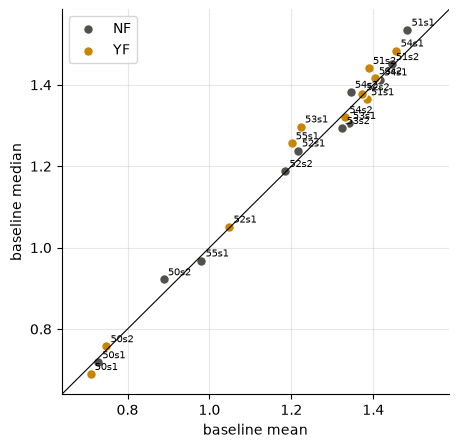

In [3]:
cmp = cond.assign(diff=cond.base_median - cond.base_mean)
display(cmp.pivot_table(index=["pid", "session"], columns="filt",
                        values=["base_mean", "base_median", "diff", "floor"]).round(3))

fig, ax = plt.subplots(figsize=(5, 5))
for filt in FILTS:
    e = cond[cond.filt == filt]
    ax.scatter(e.base_mean, e.base_median, color=FCOL[filt], s=50, label=filt, edgecolor="white")
    for _, r in e.iterrows():
        ax.annotate(f"{r.pid[-2:]}s{r.session}", (r.base_mean, r.base_median), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
lim = [cond[["base_mean", "base_median"]].min().min() - 0.05, cond[["base_mean", "base_median"]].max().max() + 0.05]
ax.plot(lim, lim, color="k", lw=0.8)
ax.set(xlabel="baseline mean", ylabel="baseline median", xlim=lim, ylim=lim)
ax.legend()
plt.show()

### Raw curves per session
Solid = rep 1, dashed = rep 2. Shaded band = min-max of that filter's 8
baseline trials, line inside = baseline (`BASE_STAT`). Dotted = floor (reference).

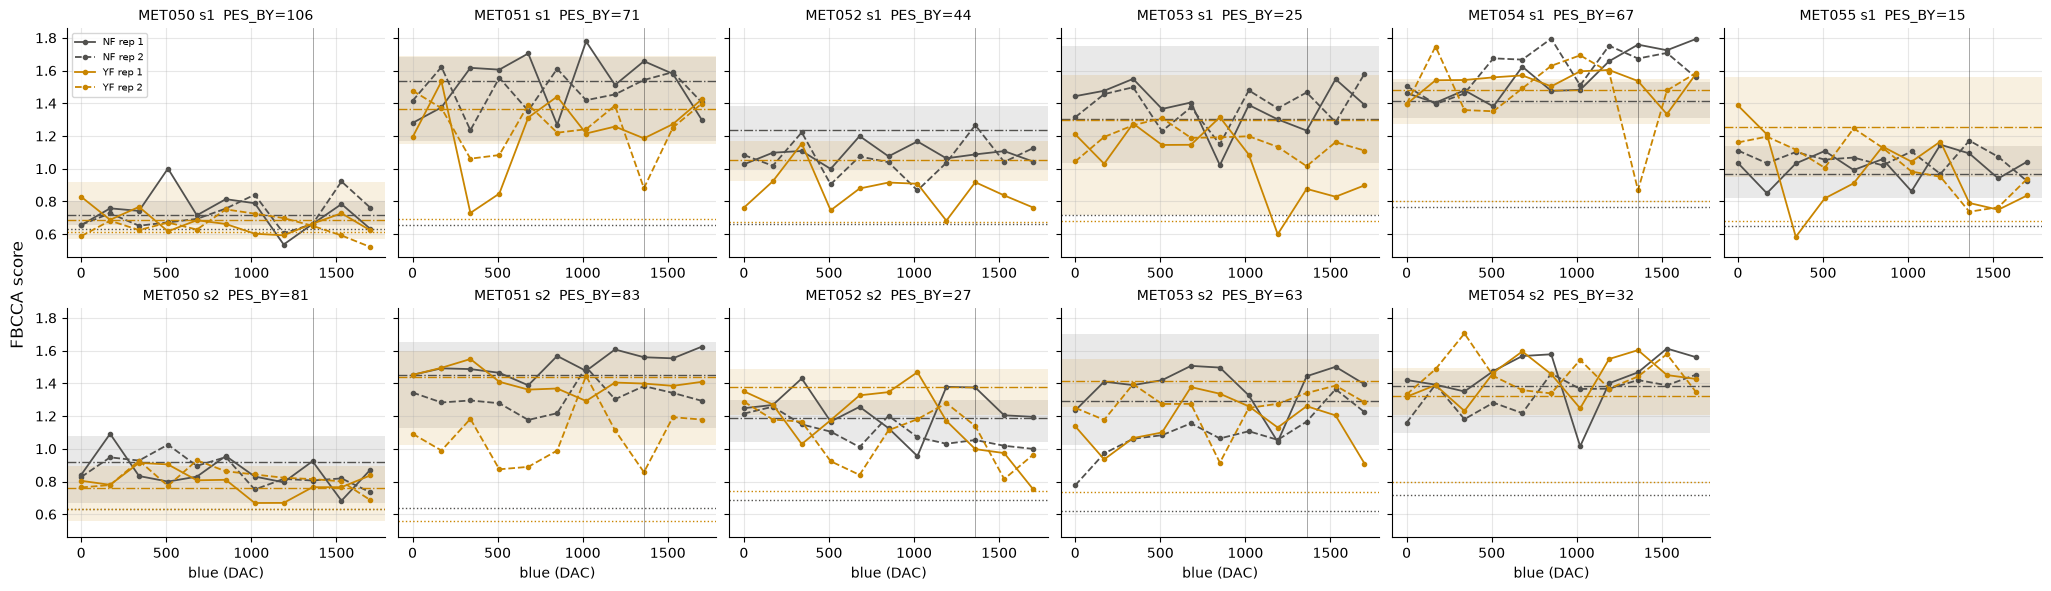

In [4]:
def grid(h=2.9, w=3.4, **kw):
    fig, axes = plt.subplots(len(SESSIONS), len(PIDS), figsize=(w * len(PIDS), h * len(SESSIONS)),
                             squeeze=False, layout="constrained", **kw)
    return fig, axes

def cells(xlabel="blue (DAC)"):
    fig, axes = grid(sharey=True)
    for j, pid in enumerate(PIDS):
        for i, s in enumerate(SESSIONS):
            ax = axes[i, j]
            if (pid, s) not in PES.index:
                ax.set_visible(False)
                continue
            pes = PES[(pid, s)]
            ax.set_title(f"{pid} s{s}  PES_BY={pes:.0f}" if pd.notna(pes) else f"{pid} s{s}", fontsize=10)
            yield ax, pid, s
    for ax in axes[-1]: ax.set_xlabel(xlabel)
    axes[0, 0].legend(fontsize=7)
    return

def show(gen, ylabel, name=None):
    for ax, *_ in gen: pass
    plt.gcf().supylabel(ylabel)
    if name: save(name)
    plt.show()

def raw_cell():
    for ax, pid, s in cells():
        for filt in FILTS:
            c = cond[(cond.pid == pid) & (cond.session == s) & (cond.filt == filt)].iloc[0]
            ax.axhspan(c.base_min, c.base_max, color=FCOL[filt], alpha=0.12, lw=0)
            ax.axhline(c.base, color=FCOL[filt], ls="-.", lw=1)
            ax.axhline(c.floor, color=FCOL[filt], ls=":", lw=1)
            for rep in (1, 2):
                d = br[(br.pid == pid) & (br.session == s) & (br.filt == filt) & (br.rep == rep)]
                ax.plot(d.blue, d.raw, "o" + SLS[rep], color=FCOL[filt], ms=3, lw=1.3, label=f"{filt} rep {rep}")
        ax.axvline(1360, color="k", lw=0.6, alpha=0.4)
        yield ax, pid, s

show(raw_cell(), "FBCCA score", "raw_curves")

### Baseline trials, trial by trial
Checks for drift or warm-up within the 8-trial base run.

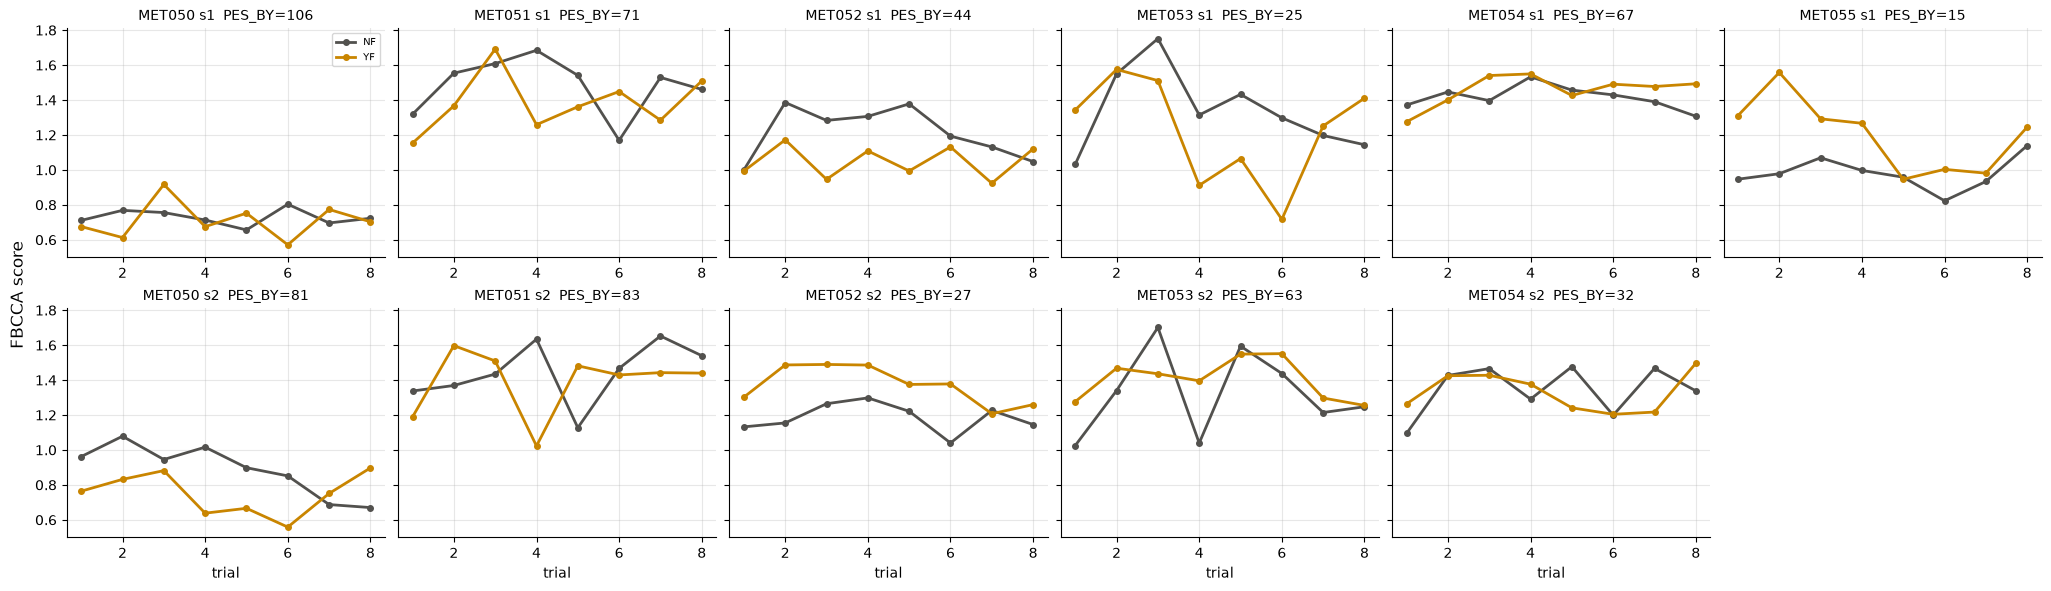

In [5]:
def base_cell():
    for ax, pid, s in cells("trial"):
        for filt in FILTS:
            e = base[(base.pid == pid) & (base.session == s) & (base.filt == filt)]
            ax.plot(e.trial, e.raw, "o-", color=FCOL[filt], ms=4, label=filt)
        yield ax, pid, s

show(base_cell(), "FBCCA score")

### Anchor check: is the blue = 0 step inside the baseline's own variability?
The blue = 0 step and the 8-trial base run show the same stimulus (red 1800
vs blue 0). Box + dots = the 8 baseline trials; X = the blue = 0 step of each
rep. Table: percentile of each rep's blue = 0 value within its baseline
trials (0 = below every baseline trial, 100 = above every one).

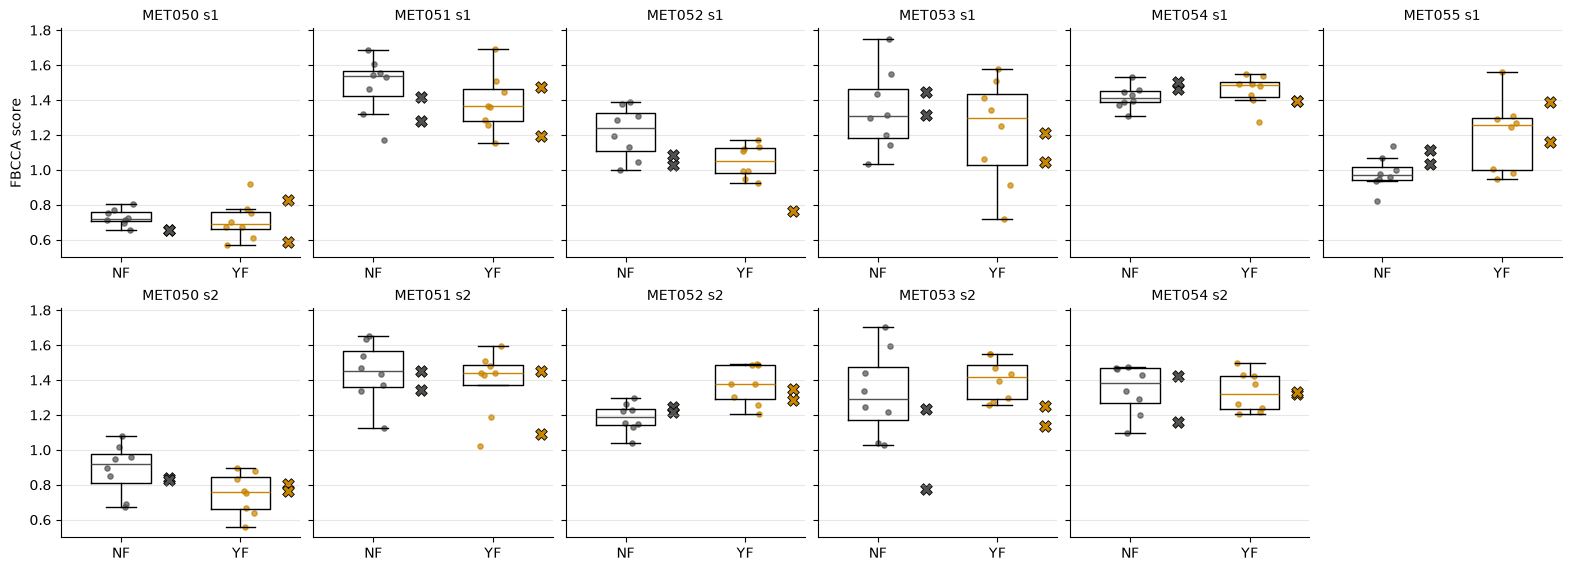

blue = 0 step inside baseline min-max: 38/43


filt              NF          YF      
rep                1     2     1     2
pid    session                        
MET050 1         0.0  12.0  88.0  12.0
       2        25.0  25.0  62.0  50.0
MET051 1        12.0  25.0  12.0  75.0
       2        50.0  25.0  62.0  12.0
MET052 1        12.0  25.0   0.0   NaN
       2        75.0  50.0  38.0  25.0
MET053 1        75.0  62.0  38.0  25.0
       2        38.0   0.0   0.0   0.0
MET054 1        88.0  88.0  12.0  12.0
       2        50.0  12.0  50.0  50.0
MET055 1        75.0  88.0  88.0  38.0

In [6]:
b0 = br[br.blue == 0]
fig, axes = grid(h=2.8, w=2.6, sharey=True)
for j, pid in enumerate(PIDS):
    for i, s in enumerate(SESSIONS):
        ax = axes[i, j]
        if (pid, s) not in PES.index:
            ax.set_visible(False)
            continue
        for k, filt in enumerate(FILTS):
            y = base[(base.pid == pid) & (base.session == s) & (base.filt == filt)].raw
            ax.boxplot(y, positions=[k], widths=0.5, showfliers=False, medianprops=dict(color=FCOL[filt]))
            ax.scatter(k + rng.uniform(-0.12, 0.12, len(y)), y, color=FCOL[filt], s=14, alpha=0.7)
            z = b0[(b0.pid == pid) & (b0.session == s) & (b0.filt == filt)]
            ax.scatter(np.full(len(z), k + 0.4), z.raw, marker="X", s=70, color=FCOL[filt], edgecolor="k", lw=0.6)
        ax.set_xticks([0, 1], FILTS)
        ax.set_title(f"{pid} s{s}", fontsize=10)
        ax.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("FBCCA score")
save("anchor")
plt.show()

pct = b0.merge(base.groupby(key).raw.apply(np.array).rename("bt").reset_index(), on=key)
pct["pctile"] = [100 * (v > bt).mean() + 50 * (v == bt).mean() for v, bt in zip(pct.raw, pct.bt)]
pct["inside_range"] = [bt.min() <= v <= bt.max() for v, bt in zip(pct.raw, pct.bt)]
print(f"blue = 0 step inside baseline min-max: {pct.inside_range.sum()}/{len(pct)}")
pct.pivot_table(index=["pid", "session"], columns=["filt", "rep"], values="pctile").round(0)

### Rep 1 vs rep 2 agreement
Each point = one blue step in one condition (normalized).

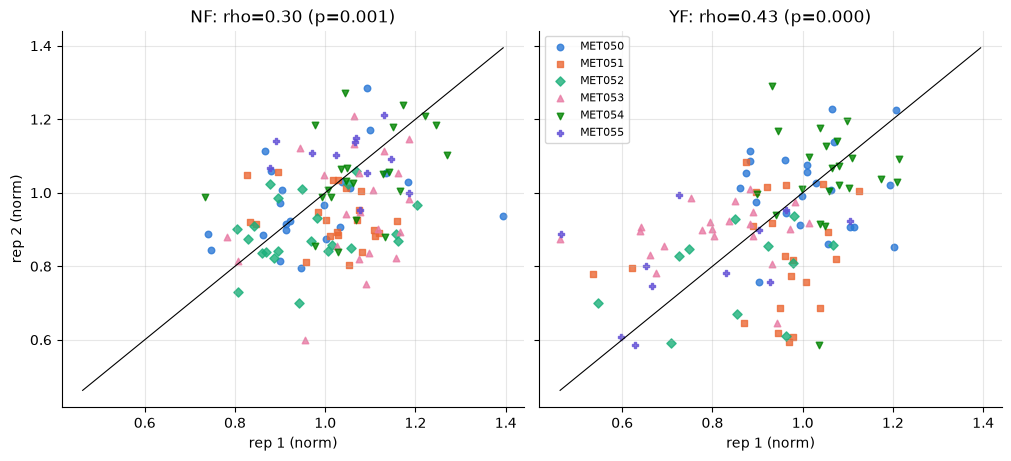

In [7]:
w = br.pivot_table(index=key + ["blue"], columns="rep", values="norm").dropna().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained", sharex=True, sharey=True)
for ax, filt in zip(axes, FILTS):
    e = w[w.filt == filt]
    for pid in PIDS:
        q = e[e.pid == pid]
        ax.scatter(q[1], q[2], color=PC[pid], marker=PM[pid], s=22, label=pid, alpha=0.8)
    r, p = spearmanr(e[1], e[2])
    lim = [w[[1, 2]].min().min(), w[[1, 2]].max().max()]
    ax.plot(lim, lim, color="k", lw=0.8)
    ax.set(title=f"{filt}: rho={r:.2f} (p={p:.3f})", xlabel="rep 1 (norm)")
axes[0].set_ylabel("rep 2 (norm)")
axes[1].legend(fontsize=8)
plt.show()

## M1. NF and YF against FM100 blue-yellow

Idea: with intact blue vision NF and YF differ (the filter removes the blue
part of the stimulus); with blue deficits they converge. NF sits above YF in
this data, so convergence means the NF - YF gap shrinks as PES_BY rises
(negative rho; higher PES_BY = worse).

### Per-session curves (normalized), gap shaded

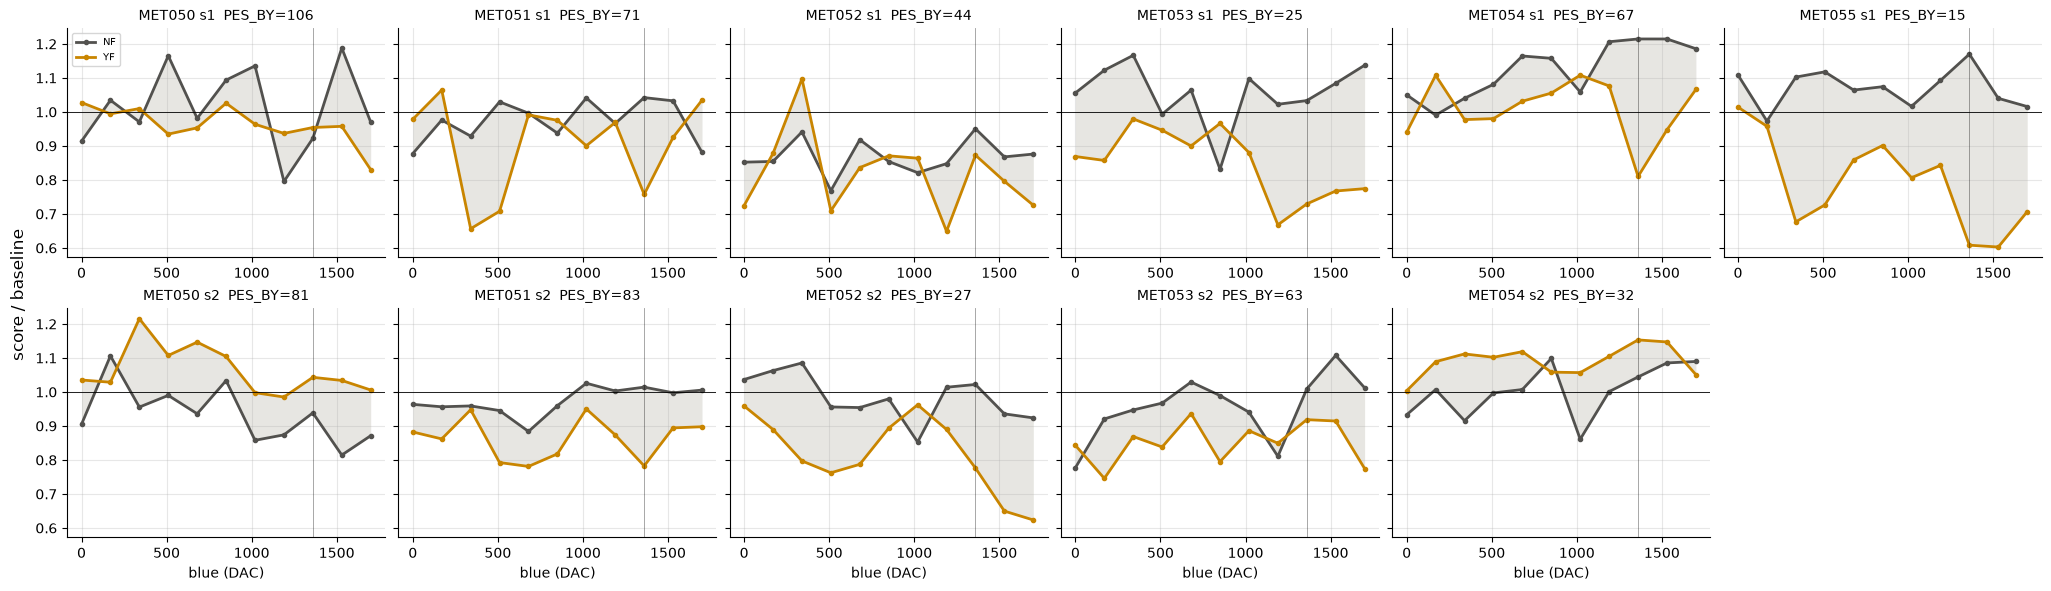

In [8]:
def curve_cell(col):
    for ax, pid, s in cells():
        d = curves[(curves.pid == pid) & (curves.session == s)].pivot(index="blue", columns="filt", values=col)
        for filt in FILTS:
            ax.plot(d.index, d[filt], "o-", color=FCOL[filt], ms=3, label=filt)
        ax.fill_between(d.index, d.NF, d.YF, color="#c3c2b7", alpha=0.4, lw=0)
        ax.axvline(1360, color="k", lw=0.6, alpha=0.4)
        ax.axhline(1, color="k", lw=0.6)
        yield ax, pid, s

show(curve_cell("norm"), "score / baseline")

### Curves colored by PES_BY, NF and YF separately
One line per session, darker = worse FM100 blue-yellow. Rows: all sessions,
session 1 only, session 2 only.

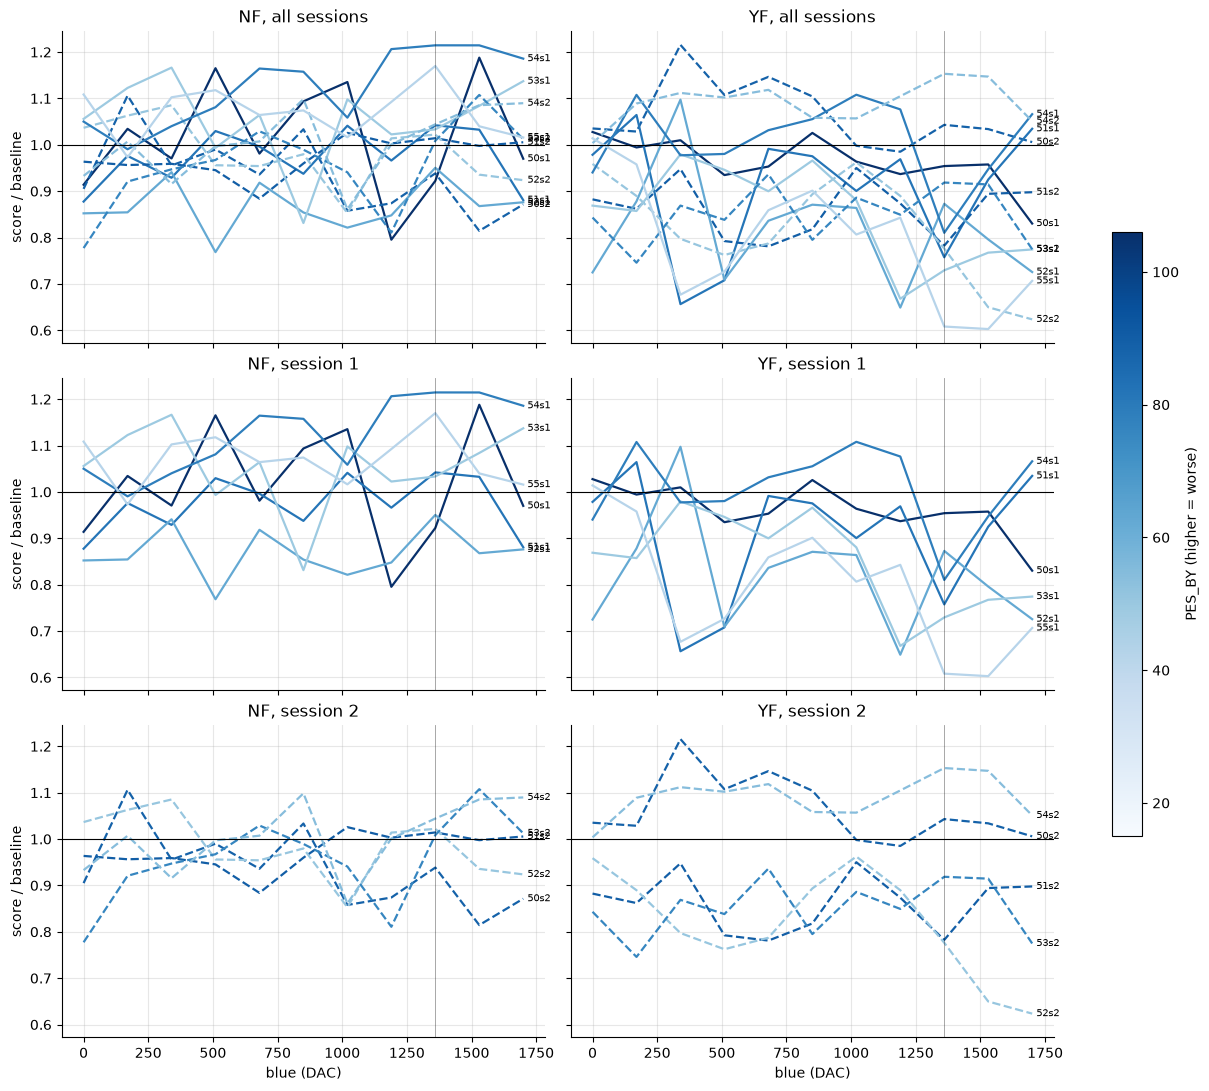

In [9]:
fmc = curves.merge(sessions, on=["pid", "session"]).dropna(subset=["PES_BY"])
cmap = plt.get_cmap("Blues")
vmin, vmax = fmc.PES_BY.min(), fmc.PES_BY.max()
shade = lambda v: cmap(0.3 + 0.7 * (v - vmin) / (vmax - vmin))
subsets = [("all sessions", SESSIONS)] + [(f"session {s}", [s]) for s in SESSIONS]

fig, axes = plt.subplots(len(subsets), 2, figsize=(12, 3.6 * len(subsets)), layout="constrained",
                         sharex=True, sharey=True)
for row, (name, ss) in zip(axes, subsets):
    for ax, filt in zip(row, FILTS):
        for (pid, s), d in fmc[(fmc.filt == filt) & fmc.session.isin(ss)].groupby(["pid", "session"]):
            ax.plot(d.blue, d.norm, SLS[s], color=shade(d.PES_BY.iloc[0]), lw=1.6)
            ax.annotate(f"{pid[-2:]}s{s}", (d.blue.iloc[-1], d.norm.iloc[-1]), fontsize=7,
                        xytext=(3, 0), textcoords="offset points", va="center")
        ax.axhline(1, color="k", lw=0.8)
        ax.axvline(1360, color="k", lw=0.6, alpha=0.4)
        ax.set_title(f"{filt}, {name}")
for ax in axes[:, 0]: ax.set_ylabel("score / baseline")
for ax in axes[-1]: ax.set_xlabel("blue (DAC)")
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)), ax=axes,
             label="PES_BY (higher = worse)", shrink=0.6)
save("curves_by_pesby")
plt.show()

### Heatmaps
Rows = sessions sorted by PES_BY (best at top, PES_BY in brackets), columns
= blue step. Each cell is one session's normalized value at that step
(score / that session's baseline); nothing is rescaled per column. NF and YF:
red = above baseline, blue = below (centered at 1). Gap: red = NF above YF
(centered at 0).

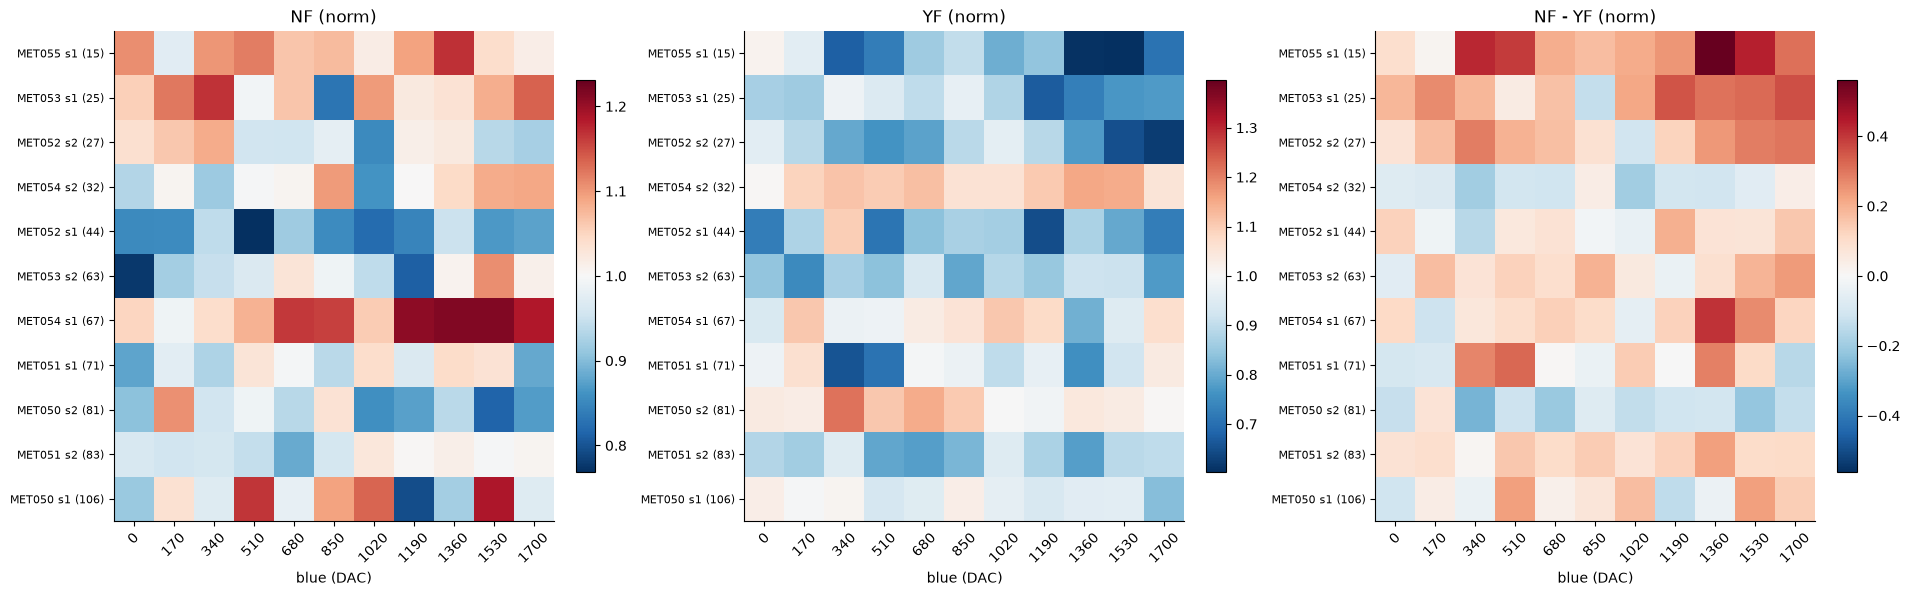

In [10]:
gap = curves.pivot_table(index=["pid", "session", "blue"], columns="filt", values="norm")
gap = (gap.NF - gap.YF).rename("norm").reset_index()

panels = [(f"NF (norm)", curves[curves.filt == "NF"], 1), (f"YF (norm)", curves[curves.filt == "YF"], 1),
          ("NF - YF (norm)", gap, 0)]
fig, axes = plt.subplots(1, 3, figsize=(19, 0.35 * len(sessions) + 2), layout="constrained")
for ax, (title, d, center) in zip(axes, panels):
    h = (d.merge(sessions, on=["pid", "session"])
         .pivot_table(index=["PES_BY", "pid", "session"], columns="blue", values="norm").sort_index())
    v = np.nanmax(np.abs(h.values - center))
    im = ax.imshow(h.values, cmap="RdBu_r", vmin=center - v, vmax=center + v, aspect="auto")
    ax.set_xticks(range(len(BLUE)), [f"{b:.0f}" for b in BLUE], rotation=45)
    ax.set_yticks(range(len(h)), [f"{p} s{s} ({b:.0f})" for b, p, s in h.index], fontsize=8)
    ax.set(title=title, xlabel="blue (DAC)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
save("heatmaps")
plt.show()

### Session features vs PES_BY
For each session and measure (NF, YF, NF - YF; all normalized): average over
`mean` = all 11 steps, `low` = 0-340 (first 3), `high` = 1360-1700 (last 3).
Filled = session 1, open = session 2; lines join a participant's sessions.
Titles: Spearman over sessions, and over participants (each participant's
sessions averaged first). Each block is shown with all participants and
without MET050 (weakest responder, highest PES_BY).

In [11]:
long = pd.concat([curves[["pid", "session", "filt", "blue", "norm"]],
                  gap.assign(filt="gap")])
feat = pd.DataFrame([
    dict(pid=pid, session=s, measure=m, window=wn, value=d[d.blue.isin(wb)].norm.mean())
    for (pid, s, m), d in long.groupby(["pid", "session", "filt"]) for wn, wb in WINDOWS.items()
]).merge(sessions, on=["pid", "session"])

def rho_both(df, x, y):
    df = df.dropna(subset=[x, y])
    r1, p1 = spearmanr(df[x], df[y])
    m = df.groupby("pid")[[x, y]].mean()
    r2, p2 = spearmanr(m[x], m[y])
    return r1, p1, len(df), r2, p2, len(m)

def scatter_vs(measure, drop=(), x="PES_BY"):
    df = feat[(feat.measure == measure) & ~feat.pid.isin(drop)].pivot_table(
        index=["pid", "session", x], columns="window", values="value").reset_index()
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained")
    for ax, y in zip(axes, WINDOWS):
        for pid in df.pid.unique():
            d = df[df.pid == pid].sort_values("session")
            ax.plot(d[x], d[y], "-", color=PC[pid], lw=1, alpha=0.6)
            for _, r in d.iterrows():
                ax.scatter(r[x], r[y], color=PC[pid], marker=PM[pid], s=60, lw=1.5, zorder=3,
                           facecolor=PC[pid] if r.session == 1 else "white")
                ax.annotate(f"{pid[-2:]}s{r.session}", (r[x], r[y]), fontsize=7, xytext=(4, 4),
                            textcoords="offset points")
        r1, p1, n1, r2, p2, n2 = rho_both(df, x, y)
        ax.axhline(0 if measure == "gap" else 1, color="k", lw=0.6)
        ax.set(xlabel=x, ylabel=f"{measure} {y} (norm)",
               title=f"{measure} {y}\nsessions: rho={r1:.2f} p={p1:.3f} n={n1}\n"
                     f"participants: rho={r2:.2f} p={p2:.3f} n={n2}")
        ax.title.set_fontsize(9)
    fig.suptitle(f"{measure}" + (f" without {', '.join(drop)}" if drop else ""), fontweight="bold")
    if not drop: save(f"{measure}_vs_pesby")
    plt.show()

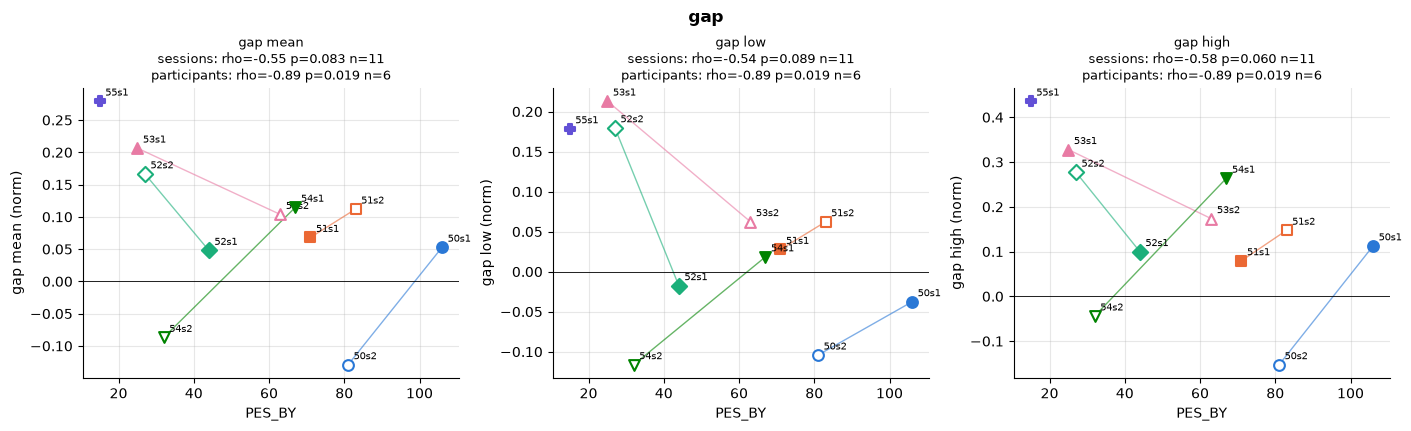

In [12]:
scatter_vs('gap', drop=())

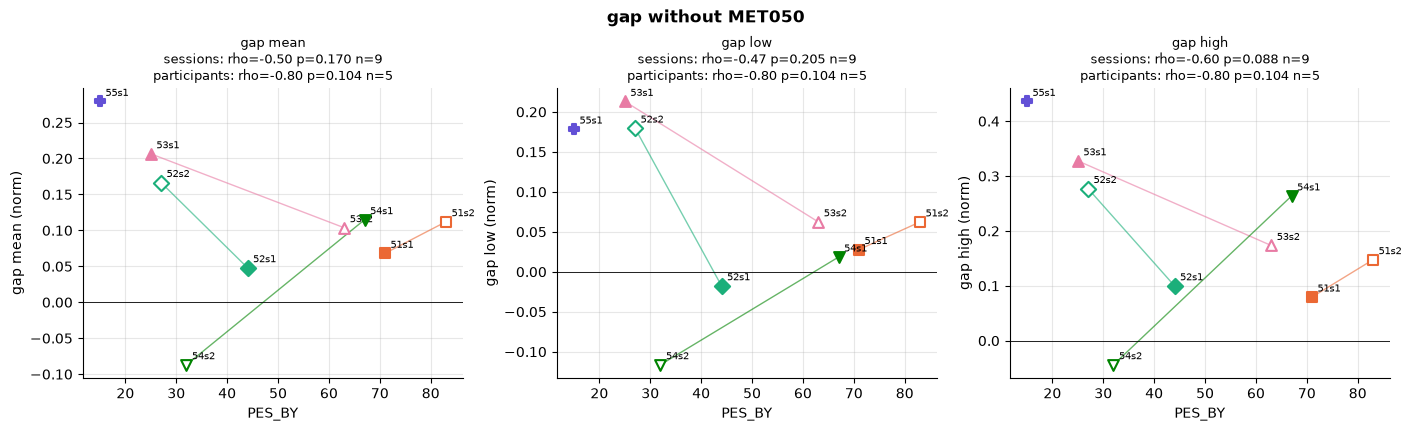

In [13]:
scatter_vs('gap', drop=("MET050",))

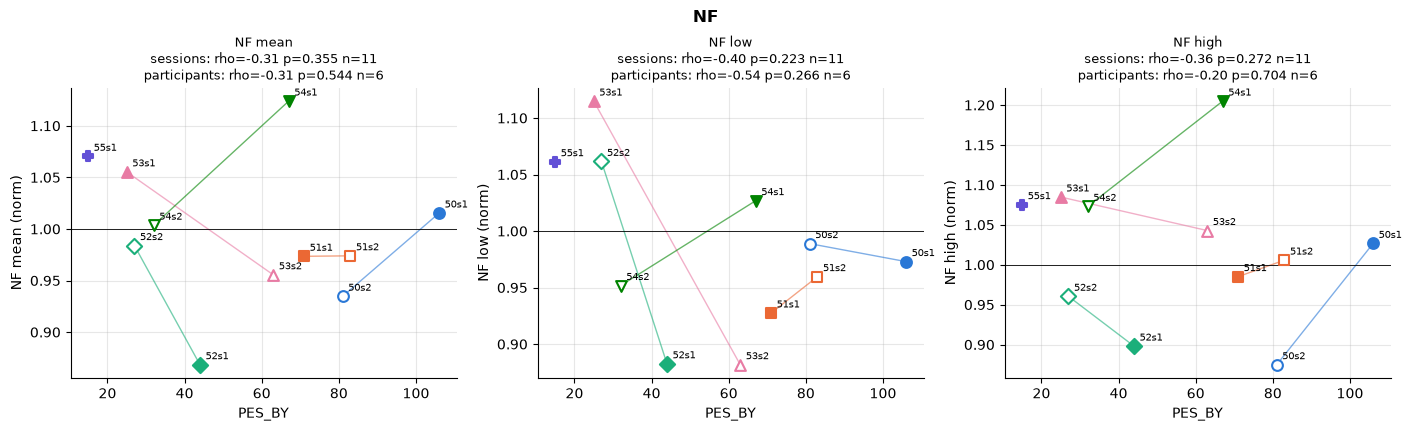

In [14]:
scatter_vs('NF', drop=())

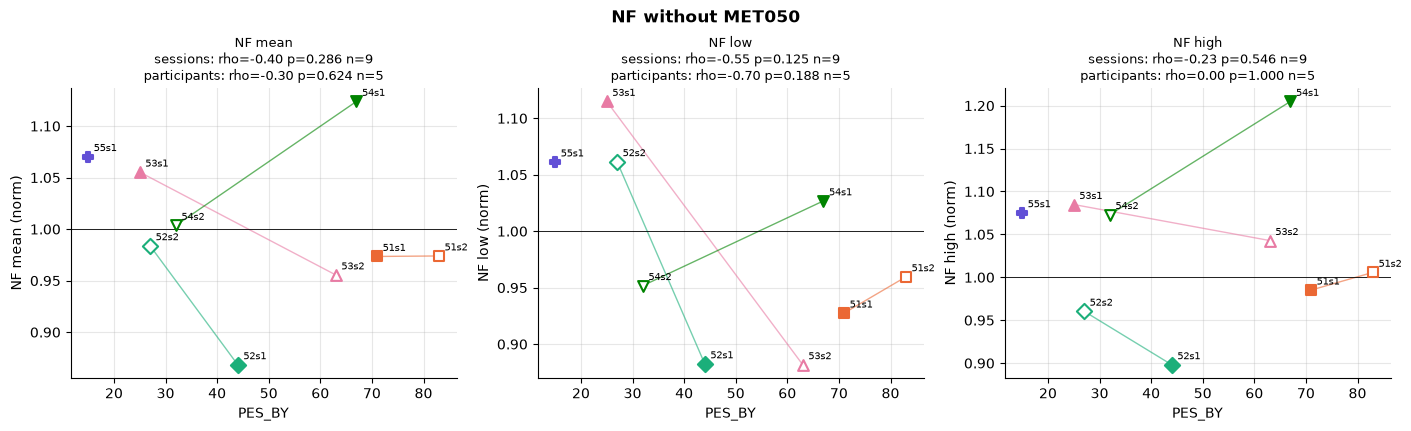

In [15]:
scatter_vs('NF', drop=("MET050",))

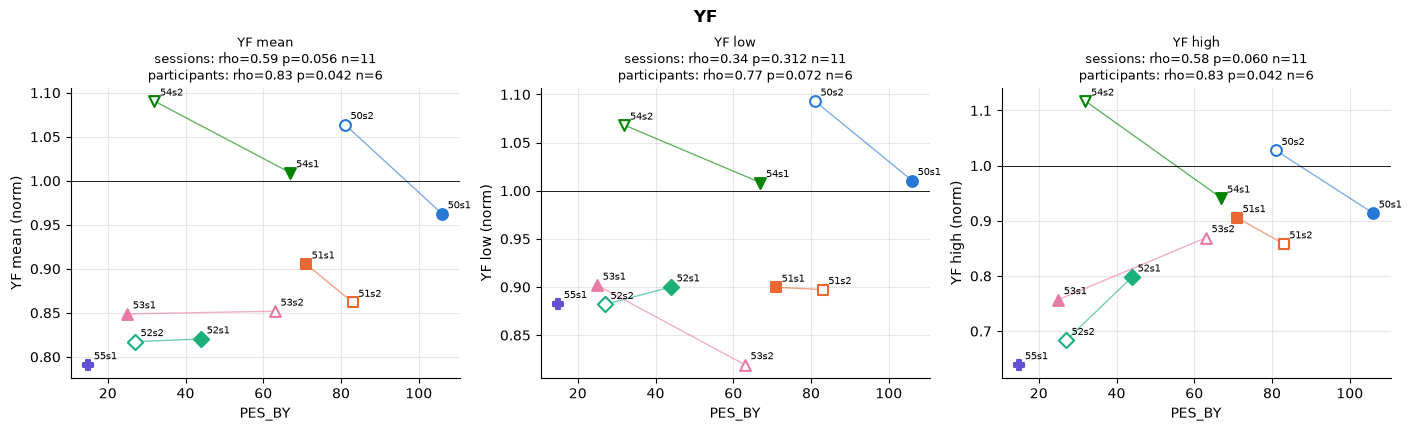

In [16]:
scatter_vs('YF', drop=())

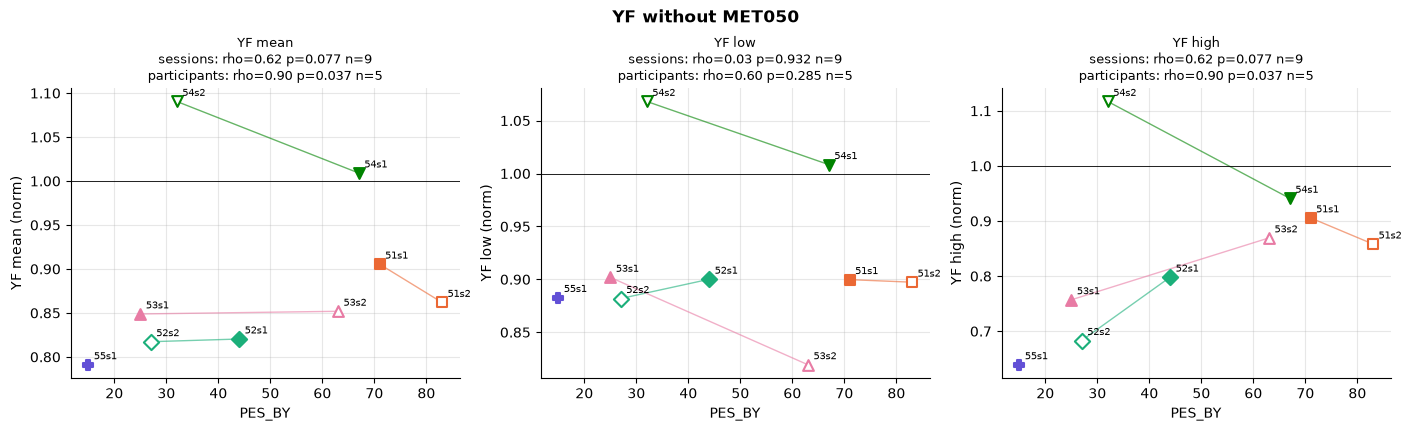

In [17]:
scatter_vs('YF', drop=("MET050",))

### Summary table
Spearman rho over sessions (p), every measure x window x FM100 score, with
and without MET050.

In [18]:
tab = {}
for drop in [False, True]:
    f = feat[feat.pid != "MET050"] if drop else feat
    for (m, wn), d in f.groupby(["measure", "window"]):
        for x in ["PES_BY", "PES_RG", "TES"]:
            d2 = d.dropna(subset=[x])
            r, p = spearmanr(d2[x], d2.value)
            tab[("no MET050" if drop else "all", m, wn, x)] = f"{r:+.2f} ({p:.3f})"
pd.Series(tab).unstack()

PES_BY         PES_RG            TES
all       NF  high  -0.36 (0.272)  -0.30 (0.369)  -0.33 (0.326)
              low   -0.40 (0.223)  -0.06 (0.863)  -0.27 (0.417)
              mean  -0.31 (0.355)  -0.26 (0.449)  -0.27 (0.417)
          YF  high  +0.58 (0.060)  +0.23 (0.492)  +0.44 (0.180)
              low   +0.34 (0.312)  +0.21 (0.527)  +0.28 (0.401)
              mean  +0.59 (0.056)  +0.31 (0.354)  +0.46 (0.151)
          gap high  -0.58 (0.060)  -0.29 (0.392)  -0.44 (0.180)
              low   -0.54 (0.089)  -0.10 (0.780)  -0.35 (0.285)
              mean  -0.55 (0.083)  -0.21 (0.536)  -0.40 (0.223)
no MET050 NF  high  -0.23 (0.546)  -0.03 (0.932)  -0.17 (0.668)
              low   -0.55 (0.125)  -0.08 (0.847)  -0.38 (0.308)
              mean  -0.40 (0.286)  -0.24 (0.529)  -0.37 (0.332)
          YF  high  +0.62 (0.077)  +0.12 (0.764)  +0.42 (0.265)
              low   +0.03 (0.932)  -0.09 (0.814)  -0.03 (0.932)
              mean  +0.62 (0.077)  +0.23 (0.559)  +0.45 (0.224)
          gap high  -0.60 (0.088)  -0.08 (0.847)  -0.37 (0.332)
              low   -0.47 (0.205)  +0.19 (0.620)  -0.20 (0.606)
              mean  -0.50 (0.170)  +0.05 (0.898)  -0.27 (0.488)

### Per-step correlation profile (exploratory)
At each blue step separately: Spearman rho between that step's NF - YF
(normalized) and PES_BY, across sessions. A point below 0 means sessions with
worse blue-yellow scores have a smaller NF - YF gap at that blue level. Band
= bootstrap 95% CI resampling participants (a participant's sessions stay
together). No multiple-comparison correction; it only shows where along the
blue axis to look.

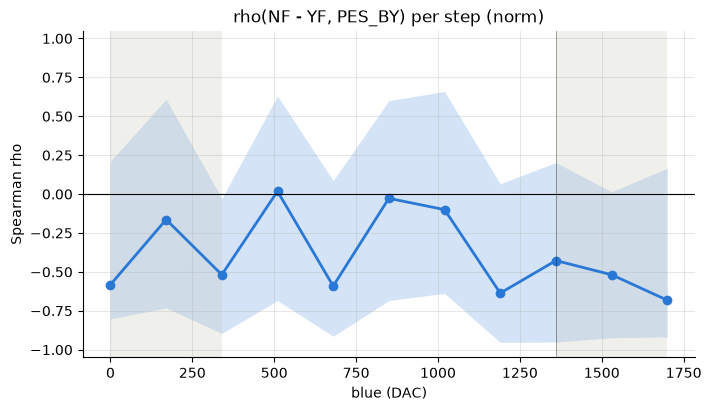

In [19]:
gpe = gap.merge(sessions, on=["pid", "session"]).dropna(subset=["PES_BY"])

def step_rho(g):
    return g.groupby("blue").apply(lambda d: spearmanr(d.PES_BY, d.norm)[0], include_groups=False)

obs = step_rho(gpe)
pids = gpe.pid.unique()
bs = np.array([step_rho(pd.concat([gpe[gpe.pid == p] for p in rng.choice(pids, len(pids))])).values
               for _ in range(2000)])
lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.fill_between(obs.index, lo, hi, color="#2a78d6", alpha=0.2, lw=0)
ax.plot(obs.index, obs.values, "o-", color="#2a78d6")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(1360, color="k", lw=0.6, alpha=0.4)
for wb in (WINDOWS["low"], WINDOWS["high"]):
    ax.axvspan(wb[0], wb[-1], color="#c3c2b7", alpha=0.25, lw=0)
ax.set(title="rho(NF - YF, PES_BY) per step (norm)", xlabel="blue (DAC)", ylabel="Spearman rho", ylim=(-1.05, 1.05))
save("step_rho")
plt.show()

## M2. Is the minimum at ~1360?

Pooled curves: each participant's sessions are averaged first, then a
participant-level bootstrap gives the 95% CI. Thin lines = individual sessions.

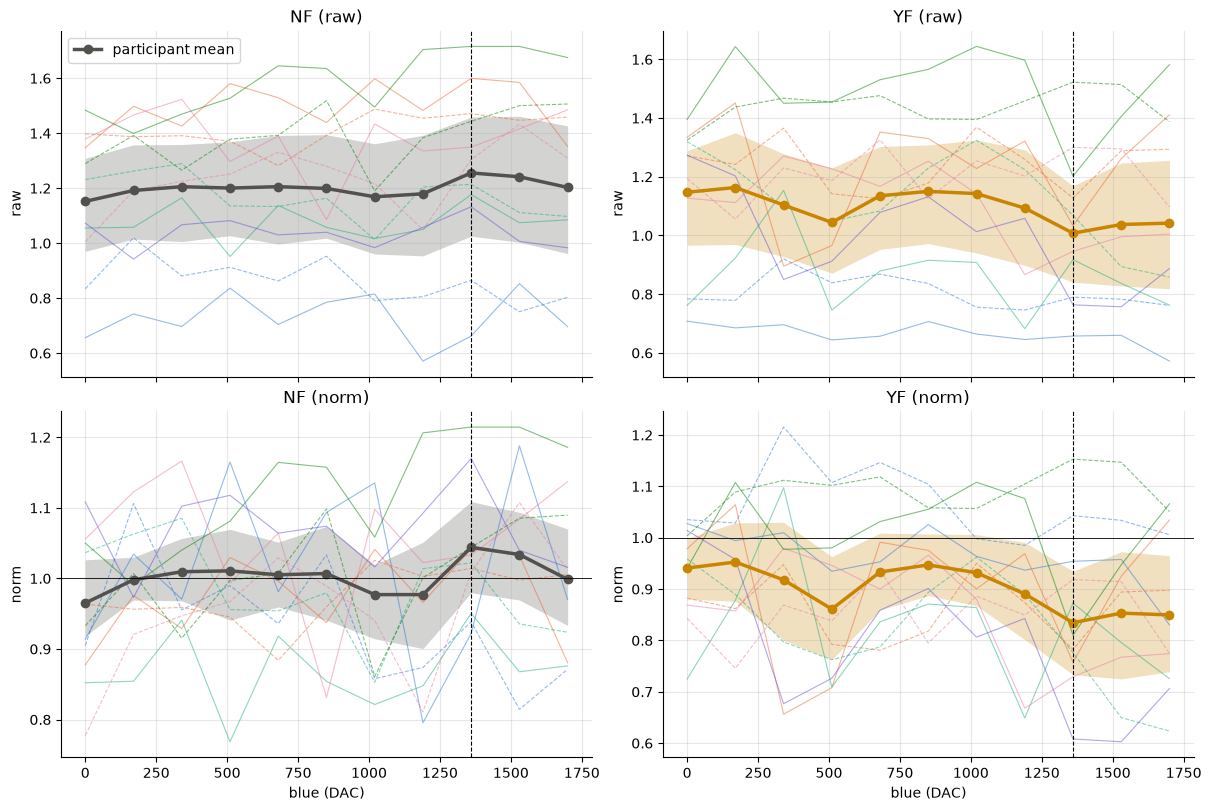

In [20]:
def boot_curve(df, col, n=2000):
    pm = df.groupby(["pid", "blue"])[col].mean().unstack()
    b = np.array([pm.loc[rng.choice(pm.index, len(pm))].mean().values for _ in range(n)])
    return pm.mean(), *np.percentile(b, [2.5, 97.5], axis=0)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharex=True)
for i, col in enumerate(["raw", "norm"]):
    for j, filt in enumerate(FILTS):
        ax = axes[i, j]
        d = curves[curves.filt == filt]
        for (pid, s), e in d.groupby(["pid", "session"]):
            ax.plot(e.blue, e[col], SLS[s], color=PC[pid], lw=0.8, alpha=0.5)
        m, lo, hi = boot_curve(d, col)
        ax.fill_between(m.index, lo, hi, color=FCOL[filt], alpha=0.25, lw=0)
        ax.plot(m.index, m.values, "o-", color=FCOL[filt], lw=2.5, label="participant mean")
        ax.axvline(1360, color="k", lw=0.8, ls="--")
        ax.set(title=f"{filt} ({col})", ylabel=col)
        if col == "norm":
            ax.axhline(1, color="k", lw=0.6)
for ax in axes[-1]: ax.set_xlabel("blue (DAC)")
axes[0, 0].legend()
save("pooled_curves")
plt.show()

### Dip profile: each step minus the mean of the two ends (0 and 1700), normalized
Negative = lower than the ends. Participant-level bootstrap 95% CI.

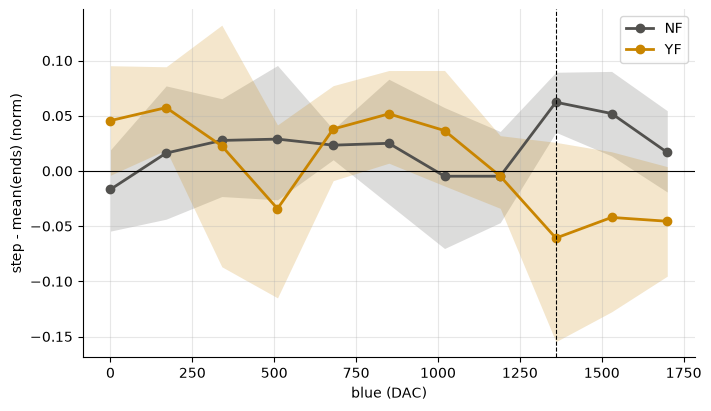

In [21]:
ends = curves[curves.blue.isin([0, 1700])].groupby(key).norm.mean().rename("ends")
dip = curves.merge(ends.reset_index(), on=key)
dip["rel"] = dip.norm - dip.ends

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for filt in FILTS:
    m, lo, hi = boot_curve(dip[dip.filt == filt], "rel")
    ax.fill_between(m.index, lo, hi, color=FCOL[filt], alpha=0.2, lw=0)
    ax.plot(m.index, m.values, "o-", color=FCOL[filt], label=filt)
ax.axhline(0, color="k", lw=0.8)
ax.axvline(1360, color="k", lw=0.8, ls="--")
ax.set(xlabel="blue (DAC)", ylabel="step - mean(ends) (norm)")
ax.legend()
plt.show()

### Contrast at 1360: value at 1360 minus mean of the ends, per session
Square = participant-level bootstrap mean and 95% CI. Filled = session 1, open = session 2.

NF: mean=+0.062  95% CI [+0.035, +0.089]  frac boot < 0 = 0.000


YF: mean=-0.061  95% CI [-0.157, +0.026]  frac boot < 0 = 0.904


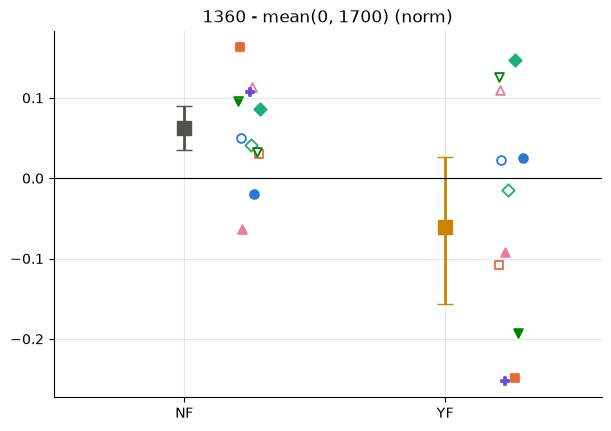

In [22]:
c1360 = dip[dip.blue == 1360]
fig, ax = plt.subplots(figsize=(6, 4.2), layout="constrained")
for k, filt in enumerate(FILTS):
    e = c1360[c1360.filt == filt]
    pm = e.groupby("pid").rel.mean()
    b = np.array([pm.loc[rng.choice(pm.index, len(pm))].mean() for _ in range(5000)])
    lo, hi = np.percentile(b, [2.5, 97.5])
    ax.errorbar(k, pm.mean(), yerr=[[pm.mean() - lo], [hi - pm.mean()]], fmt="s", color=FCOL[filt],
                ms=10, capsize=6, lw=2)
    for _, r in e.iterrows():
        ax.scatter(k + 0.25 + rng.uniform(-0.05, 0.05), r.rel, color=PC[r.pid], marker=PM[r.pid], s=40,
                   facecolor=PC[r.pid] if r.session == 1 else "white", lw=1.3)
    print(f"{filt}: mean={pm.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  frac boot < 0 = {(b < 0).mean():.3f}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks([0, 1], FILTS)
ax.set(title="1360 - mean(0, 1700) (norm)", xlim=(-0.5, 1.6))
save("contrast_1360")
plt.show()

### Where is each session's minimum? (descriptive only)
Argmin of the rep-averaged normalized curve, and of a 3-point moving average.

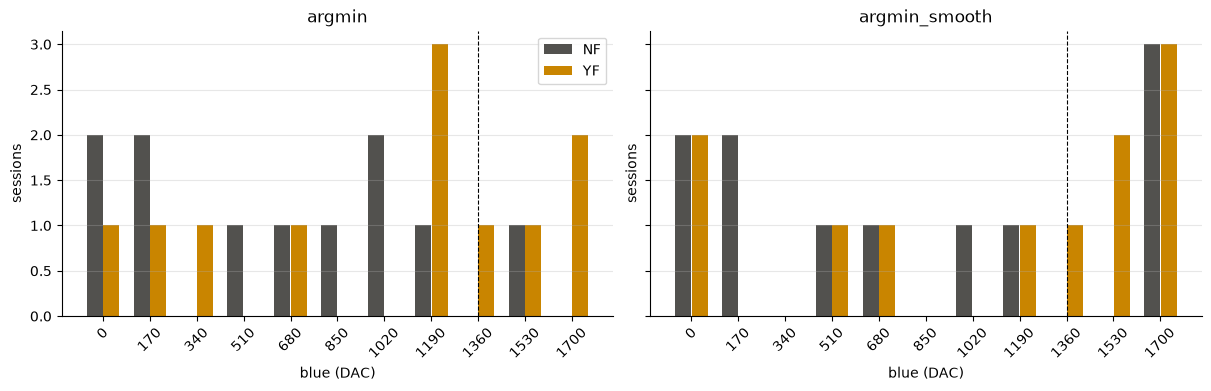

argmin         argmin_smooth        
filt                NF      YF            NF      YF
pid    session                                      
MET050 1        1190.0  1700.0        1190.0  1700.0
       2        1530.0  1190.0        1700.0  1190.0
MET051 1           0.0   340.0           0.0   510.0
       2         680.0   680.0         510.0   680.0
MET052 1         510.0  1190.0        1020.0  1700.0
       2        1020.0  1700.0        1700.0  1700.0
MET053 1         850.0  1190.0         680.0  1360.0
       2           0.0   170.0           0.0     0.0
MET054 1         170.0  1360.0         170.0  1530.0
       2        1020.0     0.0         170.0     0.0
MET055 1         170.0  1530.0        1700.0  1530.0

In [23]:
def smooth(y):
    return np.convolve(np.pad(y, 1, mode="edge"), np.ones(3) / 3, mode="valid")

am = pd.DataFrame([dict(pid=pid, session=s, filt=filt, argmin=BLUE[y.argmin()], argmin_smooth=BLUE[smooth(y).argmin()])
                   for (pid, s, filt), e in curves.groupby(key)
                   for y in [e.sort_values("blue").norm.values]])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained", sharey=True)
for ax, col in zip(axes, ["argmin", "argmin_smooth"]):
    for k, filt in enumerate(FILTS):
        cnt = am[am.filt == filt][col].value_counts().reindex(BLUE, fill_value=0)
        ax.bar(BLUE + (k - 0.5) * 60, cnt.values, width=58, color=FCOL[filt], label=filt)
    ax.axvline(1360, color="k", lw=0.8, ls="--")
    ax.set_xticks(BLUE, [f"{b:.0f}" for b in BLUE], rotation=45)
    ax.set(title=col, xlabel="blue (DAC)", ylabel="sessions")
    ax.grid(axis="x", visible=False)
axes[0].legend()
plt.show()
am.pivot_table(index=["pid", "session"], columns="filt", values=["argmin", "argmin_smooth"])

## M3. Session repeatability (light)

### Session 1 vs session 2, per feature
Identity line = perfect repeat. FM100 practice effect predicts PES_BY below the line.

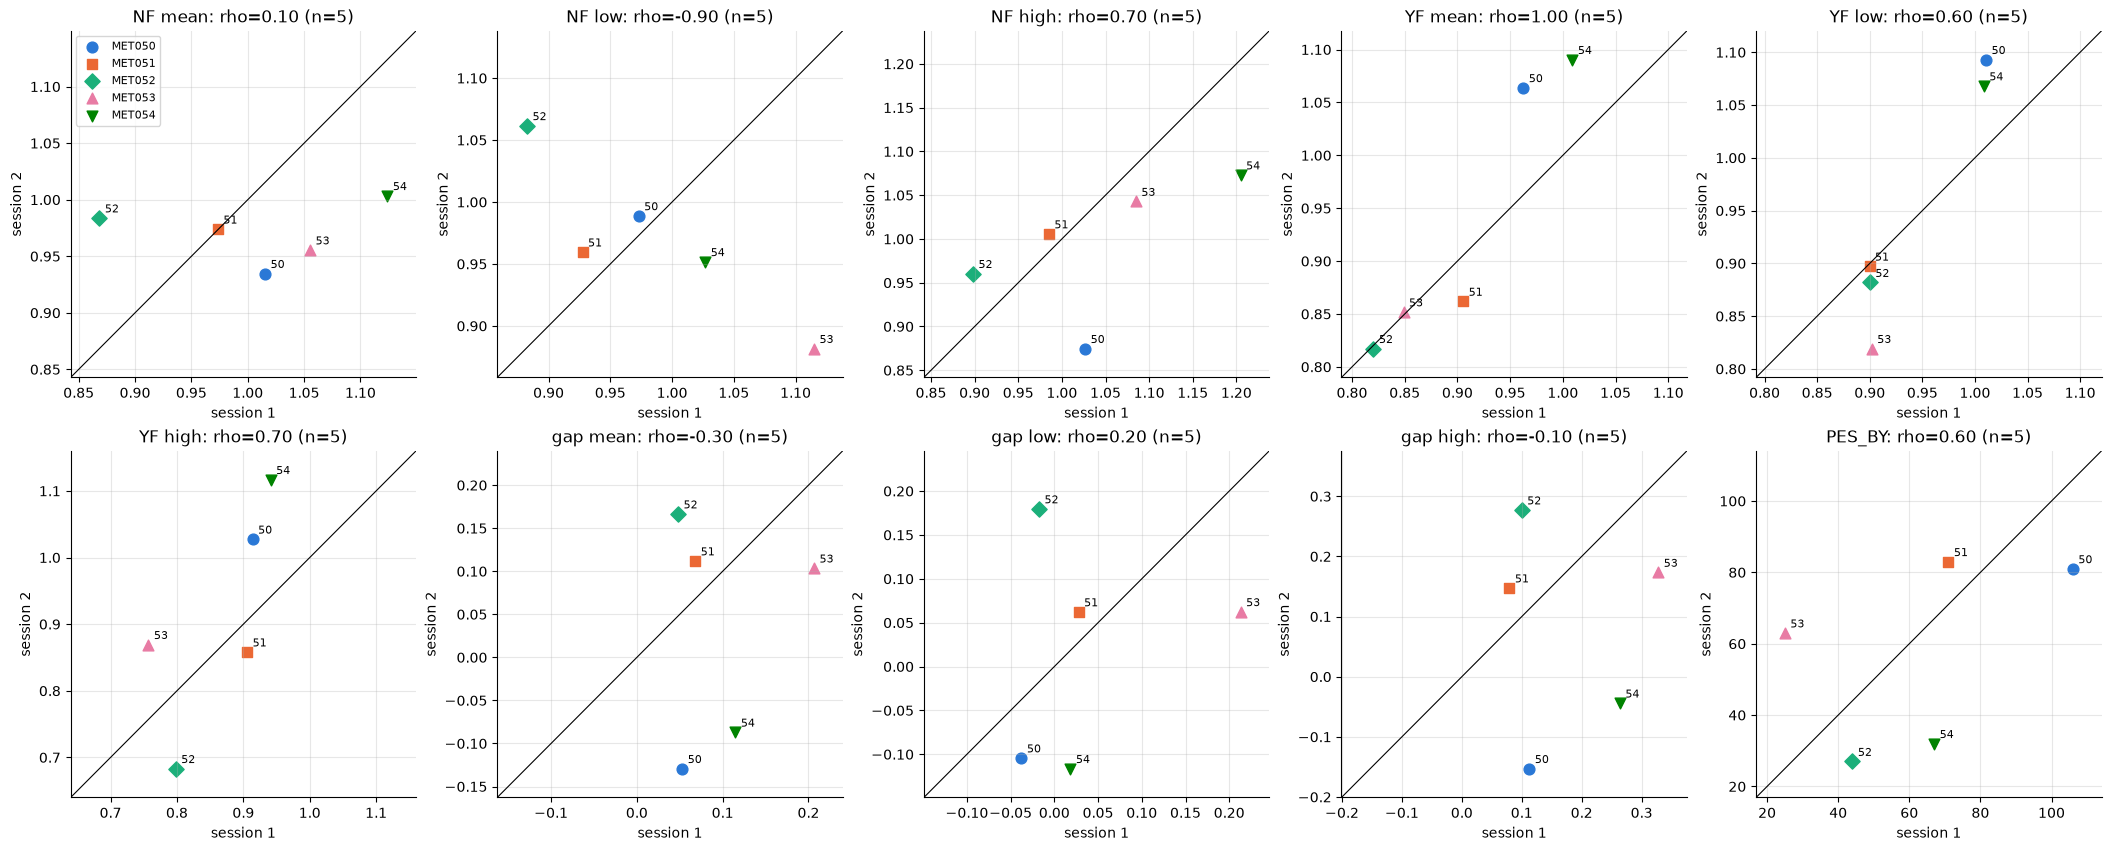

In [24]:
two = feat.pivot_table(index="pid", columns=["measure", "window", "session"], values="value")
fm2 = sessions.pivot_table(index="pid", columns="session", values="PES_BY")
items = [(f"{m} {wn}", two[(m, wn)]) for m in ["NF", "YF", "gap"] for wn in WINDOWS] + [("PES_BY", fm2)]
items = [(n, d[[1, 2]].dropna()) for n, d in items]

fig, axes = plt.subplots(2, 5, figsize=(21, 8.4), layout="constrained")
for ax, (name, d) in zip(axes.flat, items):
    for pid, r in d.iterrows():
        ax.scatter(r[1], r[2], color=PC[pid], marker=PM[pid], s=60, label=pid)
        ax.annotate(pid[-2:], (r[1], r[2]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    v = d.values
    lim = [v.min() - 0.1 * np.ptp(v), v.max() + 0.1 * np.ptp(v)]
    ax.plot(lim, lim, color="k", lw=0.8)
    rho, _ = spearmanr(d[1], d[2])
    ax.set(xlim=lim, ylim=lim, xlabel="session 1", ylabel="session 2", title=f"{name}: rho={rho:.2f} (n={len(d)})")
axes.flat[0].legend(fontsize=8)
save("sessions")
plt.show()

### ICC per blue step and per feature
ICC(A,1): two-way random, absolute agreement, single measurement (same as
`ssveps/scripts/reliability.py`), across participants with both sessions,
on the normalized values. Rough reading: < 0.5 poor, 0.5-0.75 moderate,
0.75-0.9 good. With n = 5 participants the 95% CIs are very wide.

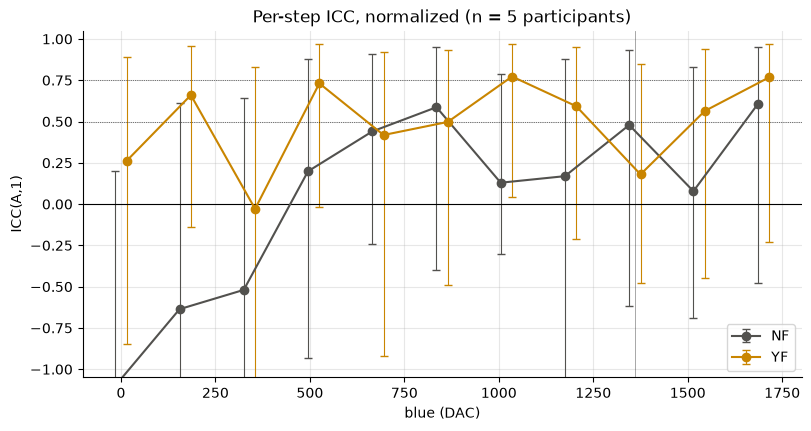

icc       ci_lo       ci_hi           p      
filt      NF    YF    NF    YF    NF    YF    NF    YF
blue                                                  
0.0    -1.10  0.26 -1.52 -0.85  0.20  0.89  0.96  0.32
170.0  -0.64  0.66 -1.47 -0.14  0.61  0.96  0.82  0.07
340.0  -0.52 -0.03 -1.27 -1.18  0.64  0.83  0.80  0.52
510.0   0.20  0.73 -0.93 -0.02  0.88  0.97  0.37  0.04
680.0   0.44  0.42 -0.24 -0.92  0.91  0.92  0.13  0.24
850.0   0.59  0.50 -0.40 -0.49  0.95  0.93  0.12  0.16
1020.0  0.13  0.77 -0.30  0.04  0.79  0.97  0.35  0.03
1190.0  0.17  0.59 -1.08 -0.21  0.88  0.95  0.39  0.09
1360.0  0.48  0.18 -0.62 -0.48  0.93  0.85  0.19  0.34
1530.0  0.08  0.56 -0.69 -0.45  0.83  0.94  0.44  0.13
1700.0  0.60  0.77 -0.48 -0.23  0.95  0.97  0.12  0.05

,measure,window,icc,ci_lo,ci_hi,p,n
0,NF,mean,0.05,-0.87,0.83,0.47,5.0
1,NF,low,-1.32,-1.59,-0.16,0.99,5.0
2,NF,high,0.53,-0.34,0.94,0.13,5.0
3,YF,mean,0.84,0.20,0.98,0.02,5.0
4,YF,low,0.80,-0.13,0.98,0.04,5.0
5,YF,high,0.58,-0.39,0.94,0.12,5.0
6,gap,mean,0.09,-0.75,0.84,0.43,5.0
7,gap,low,0.23,-1.03,0.89,0.35,5.0
8,gap,high,-0.04,-0.82,0.80,0.53,5.0
9,FM100,PES_BY,0.50,-0.74,0.94,0.18,5.0


In [25]:
import pingouin as pg

def icc_a1(d):
    """d: DataFrame indexed by pid with columns 1 and 2 (sessions)."""
    d = d[[1, 2]].dropna()
    long_ = d.reset_index().melt(id_vars="pid", var_name="session", value_name="v")
    r = pg.intraclass_corr(data=long_, targets="pid", raters="session", ratings="v")
    r = r[r.Type == "ICC(A,1)"].iloc[0]
    return pd.Series({"icc": r.ICC, "ci_lo": r.CI95[0], "ci_hi": r.CI95[1], "p": r.pval, "n": len(d)})

step_icc = pd.DataFrame([
    dict(filt=filt, blue=b, **icc_a1(e.pivot(index="pid", columns="session", values="norm")))
    for (filt, b), e in curves.groupby(["filt", "blue"])
])

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
for k, filt in enumerate(FILTS):
    e = step_icc[step_icc.filt == filt]
    x = e.blue + (k - 0.5) * 30
    ax.errorbar(x, e.icc, yerr=[e.icc - e.ci_lo, e.ci_hi - e.icc], fmt="o-", color=FCOL[filt],
                capsize=3, lw=1.5, elinewidth=0.8, label=filt)
for v in (0, 0.5, 0.75):
    ax.axhline(v, color="k", lw=0.8 if v == 0 else 0.5, ls="-" if v == 0 else ":")
ax.axvline(1360, color="k", lw=0.6, alpha=0.4)
ax.set(xlabel="blue (DAC)", ylabel="ICC(A,1)", title=f"Per-step ICC, normalized (n = {int(step_icc.n.max())} participants)",
       ylim=(-1.05, 1.05))
ax.legend()
save("step_icc")
plt.show()
display(step_icc.pivot(index="blue", columns="filt", values=["icc", "ci_lo", "ci_hi", "p"]).round(2))

feat_icc = pd.DataFrame([
    dict(measure=m, window=wn, **icc_a1(two[(m, wn)]))
    for m in ["NF", "YF", "gap"] for wn in WINDOWS
] + [dict(measure="FM100", window="PES_BY", **icc_a1(fm2))])
feat_icc.round(2)

### Curve agreement between sessions, NF vs YF
Per participant: Spearman rho between the session 1 and session 2 normalized
curves (shape agreement over the 11 steps), and mean absolute difference
between them (level + shape).

rho           mad       
filt       NF     YF     NF     YF
pid                               
MET050  0.027  0.218  0.111  0.101
MET051  0.218 -0.145  0.054  0.125
MET052  0.264  0.118  0.115  0.123
MET053  0.064 -0.118  0.133  0.099
MET054  0.591 -0.427  0.123  0.097

,rho,mad
filt,,
NF,0.233,0.107
YF,-0.071,0.109


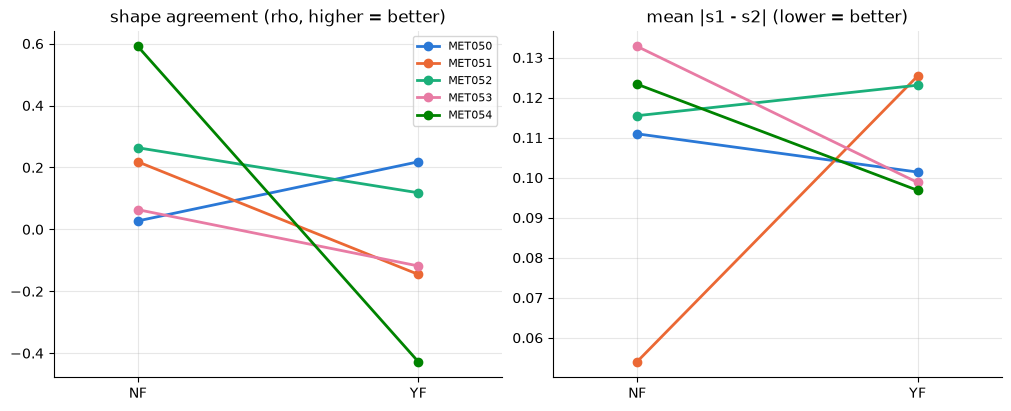

In [26]:
agree = []
for (pid, filt), d in curves.groupby(["pid", "filt"]):
    w2 = d.pivot(index="blue", columns="session", values="norm")
    if {1, 2} <= set(w2.columns):
        agree.append(dict(pid=pid, filt=filt, rho=spearmanr(w2[1], w2[2])[0], mad=(w2[1] - w2[2]).abs().mean()))
agree = pd.DataFrame(agree)
display(agree.pivot(index="pid", columns="filt", values=["rho", "mad"]).round(3))
display(agree.groupby("filt")[["rho", "mad"]].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, col in zip(axes, ["rho", "mad"]):
    w2 = agree.pivot(index="pid", columns="filt", values=col)
    for pid, r in w2.iterrows():
        ax.plot([0, 1], [r.NF, r.YF], "o-", color=PC[pid], label=pid)
    ax.set_xticks([0, 1], FILTS)
    ax.set(title={"rho": "shape agreement (rho, higher = better)", "mad": "mean |s1 - s2| (lower = better)"}[col],
           xlim=(-0.3, 1.3))
axes[0].legend(fontsize=8)
plt.show()

### Change between sessions
Does a change in the gap go with a change in PES_BY?

,gap mean,gap low,gap high,PES_BY
pid,,,,
MET050,-0.182,-0.067,-0.265,-25.0
MET051,0.044,0.035,0.068,12.0
MET052,0.119,0.197,0.177,-17.0
MET053,-0.103,-0.151,-0.154,38.0
MET054,-0.202,-0.135,-0.308,-35.0


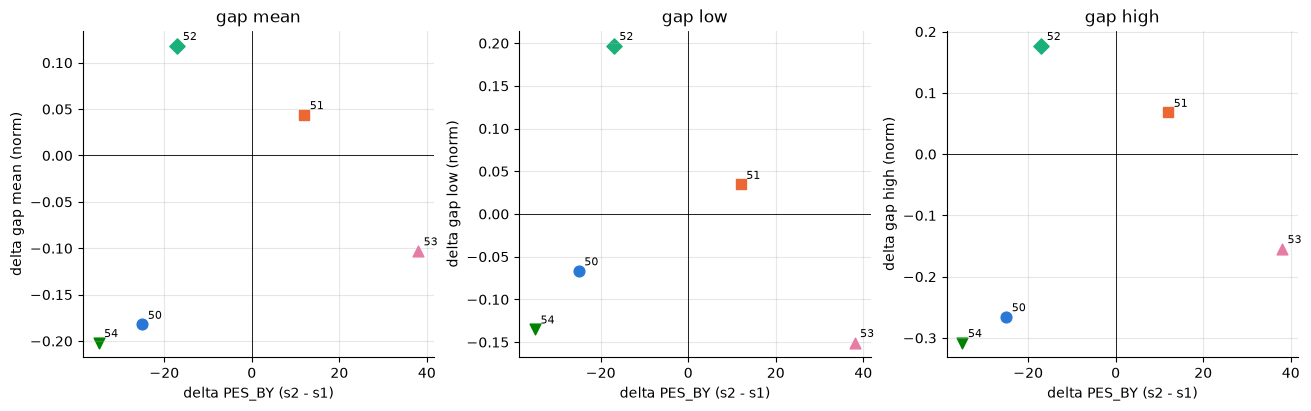

In [27]:
delta = pd.DataFrame({f"gap {wn}": two[("gap", wn)][2] - two[("gap", wn)][1] for wn in WINDOWS})
delta["PES_BY"] = fm2[2] - fm2[1]
delta = delta.dropna()
display(delta.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, y in zip(axes, [c for c in delta if c != "PES_BY"]):
    for pid, r in delta.iterrows():
        ax.scatter(r.PES_BY, r[y], color=PC[pid], marker=PM[pid], s=60)
        ax.annotate(pid[-2:], (r.PES_BY, r[y]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set(xlabel="delta PES_BY (s2 - s1)", ylabel=f"delta {y} (norm)", title=y)
plt.show()

### Curves overlaid across sessions
Solid = session 1, dashed = session 2 (normalized).

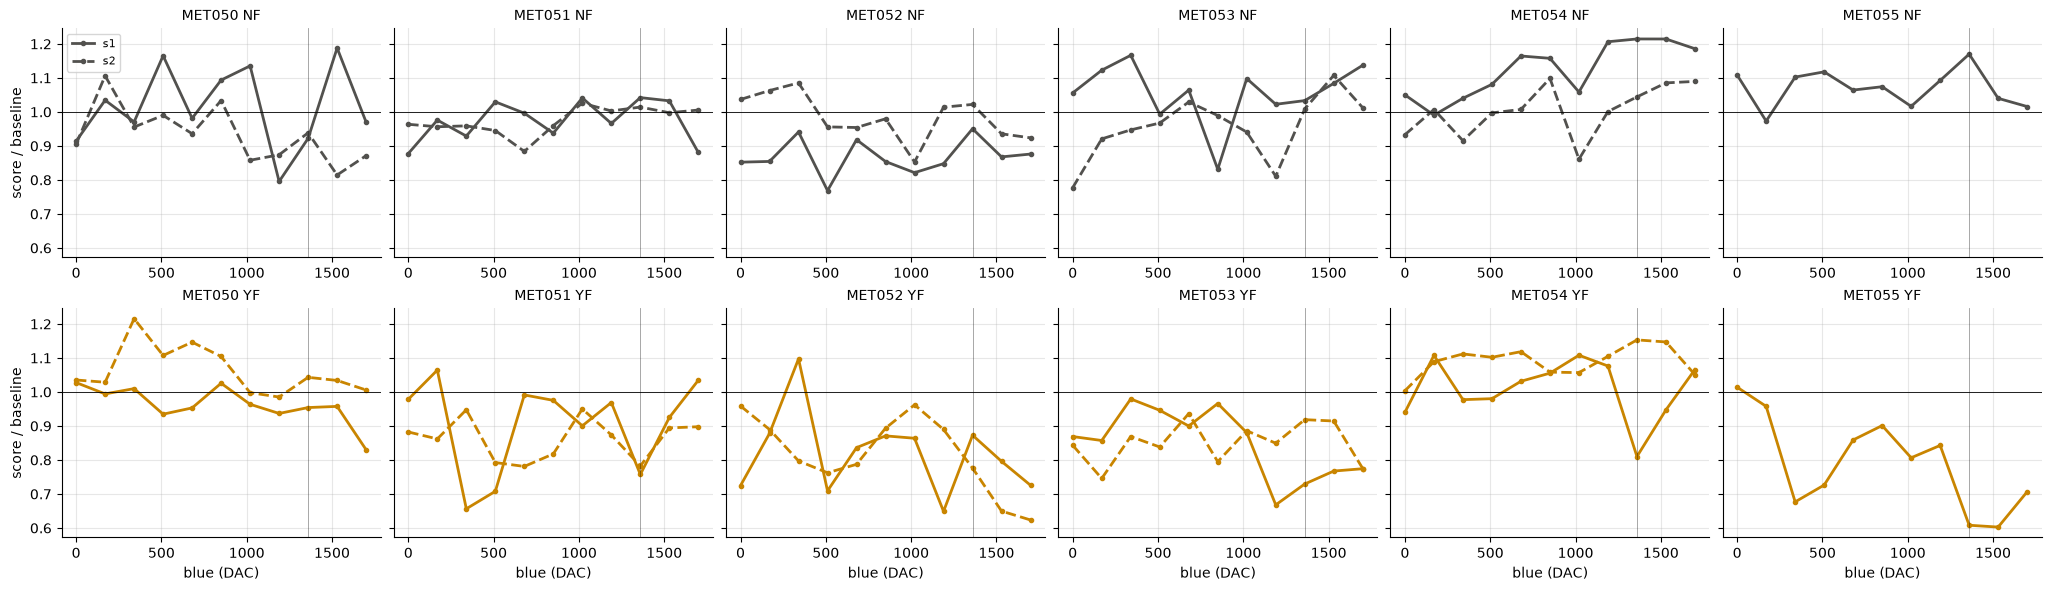

In [28]:
fig, axes = plt.subplots(2, len(PIDS), figsize=(3.4 * len(PIDS), 5.8), layout="constrained", sharey=True, squeeze=False)
for j, pid in enumerate(PIDS):
    for i, filt in enumerate(FILTS):
        ax = axes[i, j]
        for s in SESSIONS:
            e = curves[(curves.pid == pid) & (curves.session == s) & (curves.filt == filt)]
            if len(e):
                ax.plot(e.blue, e.norm, "o" + SLS[s], color=FCOL[filt], ms=3, label=f"s{s}")
        ax.axhline(1, color="k", lw=0.6)
        ax.axvline(1360, color="k", lw=0.6, alpha=0.4)
        ax.set_title(f"{pid} {filt}", fontsize=10)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel("blue (DAC)")
for ax in axes[:, 0]: ax.set_ylabel("score / baseline")
plt.show()